In [1]:
# Final pipeline running on grand arrays created for each experiment
%matplotlib widget
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.collections import LineCollection
import pandas as pd
from scipy.ndimage import uniform_filter1d
from scipy.ndimage import gaussian_filter1d
from IPython.display import HTML
from cleaning_pipeline_functions import *
from scipy.signal import savgol_filter
import cv2

### Loading data

In [2]:
# # loading from .txt files
# fish_1 = np.genfromtxt('/home/hck03/Downloads/Clip0008_1C_4N_G_7_trajectory/Clip0008_1C_4N_G_7_bee1.txt', delimiter=';')
# fish_2 = np.genfromtxt('/home/hck03/Downloads/Clip0008_1C_4N_G_7_trajectory/Clip0008_1C_4N_G_7_bee2.txt', delimiter=';')
# fish_3 = np.genfromtxt('/home/hck03/Downloads/Clip0008_1C_4N_G_7_trajectory/Clip0008_1C_4N_G_7_bee3.txt', delimiter=';')
# fish_4 = np.genfromtxt('/home/hck03/Downloads/Clip0008_1C_4N_G_7_trajectory/Clip0008_1C_4N_G_7_bee4.txt', delimiter=';')
# fish_5 = np.genfromtxt('/home/hck03/Downloads/Clip0008_1C_4N_G_7_trajectory/Clip0008_1C_4N_G_7_bee5.txt', delimiter=';')

# fishes = [fish_1, fish_2, fish_3, fish_4, fish_5]
# max_frame_no = int(max([np.max(f[:, 0]) for f in fishes])) + 1
# fish_pos = []
# for fish in fishes:
#     print(fish.shape)
#     pos = fish[:, 1:3]
#     frames = fish[:, 0].astype(int)
#     aligned_pos = np.full((max_frame_no, 2), np.nan)
#     aligned_pos[frames] = pos
#     fish_pos.append(aligned_pos)
# data_0 = np.stack(fish_pos, axis=0)
# data = data_0

In [3]:
# loading data - the grand array
file_path = Path('/home/hck03/Documents/MS_thesis/tracking_output/1c_4n_faulty/Clip0095_E2_7/data/grand_array.npy')
parent_dir = file_path.resolve().parent
data = np.load(file_path)
no_of_fishes = data.shape[0]
no_of_frames = data.shape[1]
data[np.isinf(data)] = np.nan
data.shape

(5, 1882, 2)

### Visualising the speeds - speedy trail


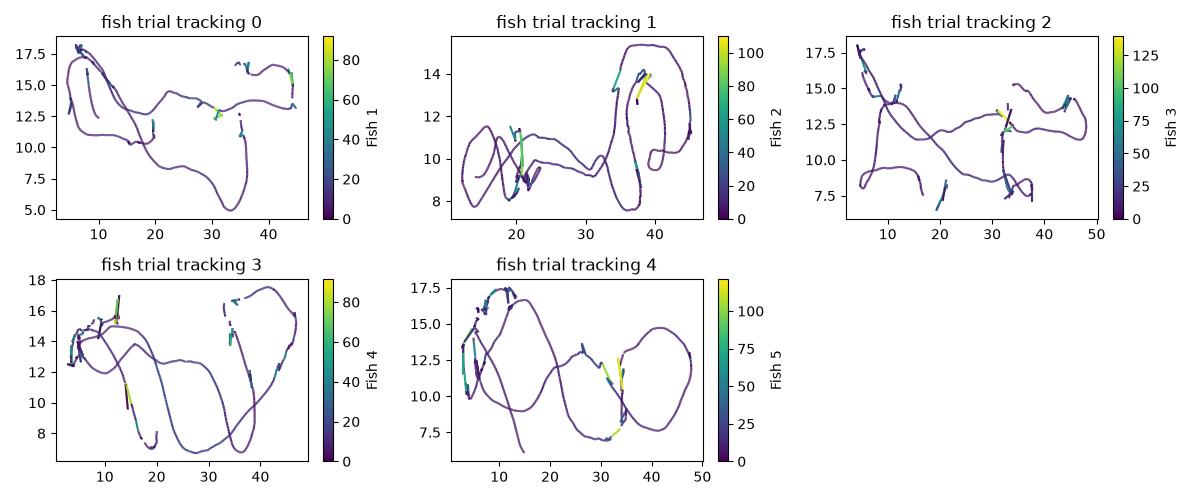

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(12, 5))
flat_axes = ax.flatten()

fig.delaxes(flat_axes[5])

for i in range(no_of_fishes):
    current_axis = flat_axes[i]
    time_steps = no_of_frames
    fish_x = data[i, :, 0]
    fish_y = data[i, :, 1]
    
    # fish_speeds = speed[i, :]
    speedy_trail(fish_x, fish_y, ax=current_axis, label=f"Fish {i+1}")
    current_axis.set_title(f"fish trial tracking {i}")

plt.tight_layout()
plt.show() 
# plt.savefig("speedy_trail_raw.png", dpi=300, bbox_inches='tight')

### Visualising corrections


k: 57, r: 0.25338227522122025
Fraction of track retained for fish 0: 0.904
k: 7, r: 0.031383393821022766
Fraction of track retained for fish 1: 0.9
k: 11, r: 0.12890232495421172
Fraction of track retained for fish 2: 0.908
k: 31, r: 0.2707962100204168
Fraction of track retained for fish 3: 0.905
k: 19, r: 0.22628408447777834
Fraction of track retained for fish 4: 0.902


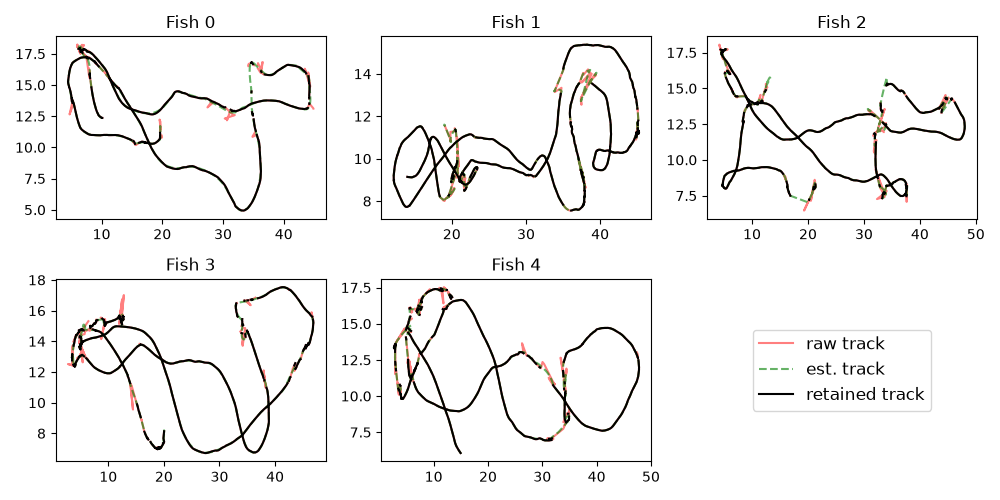

In [5]:
# Blanketting alone suffices 
fig, ax = plt.subplots(2, 3, figsize=(10,5))
flat_axes = ax.flatten()

flat_axes[5].axis('off')

data_blanket = data.copy()

ks = [None, None, 10, None, None]
# rs = [3, 3,]
# ms = ["median", "median", "median", "savgol", "median"]
# ts = [75, 70, 75, 80, 80]

for i in range(no_of_fishes):
    x = data[i, :, 0]
    y = data[i, :, 1]
    # work with gaussian, vary sigma values and threshold 
    x_med_corrected, y_med_corrected, x_med_smooth, y_med_smooth, frac = blanket(x, y, method="savgol", sigma=5, threshold=90, k=ks[i])
    data_blanket[i, :, 0] = x_med_corrected
    data_blanket[i, :, 1] = y_med_corrected
    
    flat_axes[i].plot(x, y, 'r', alpha=0.5, label='raw track')
    flat_axes[i].plot(x_med_smooth, y_med_smooth, 'g--', alpha=0.6, label='est. track')
    flat_axes[i].plot(x_med_corrected, y_med_corrected, 'k', label='retained track')

    # flat_axes[i].text(0.73, 0.8, f"frac_retained=\n{round(frac,3)}", transform=flat_axes[i].transAxes)
    flat_axes[i].set_title(f"Fish {i}")
    # just for sanity check how much of the trak is retained. Should be close to the threshold you have set
    print(f"Fraction of track retained for fish {i}:", round(frac,3))

handles, labels = flat_axes[0].get_legend_handles_labels()

flat_axes[5].legend(handles, labels, loc='center', fontsize=12)

plt.tight_layout()
# plt.legend()
plt.show()
plt.savefig("first_pass.png", dpi=300, bbox_inches='tight')

### Visualising interpolated tracks


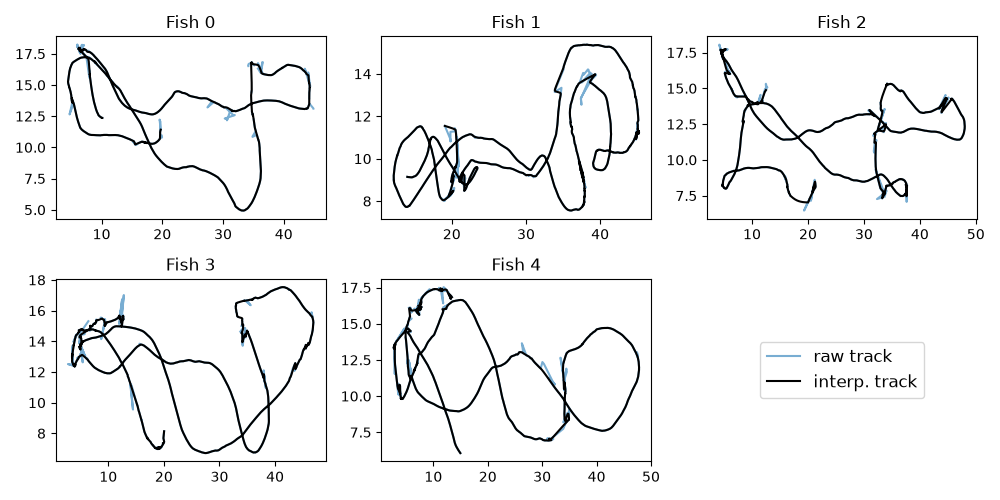

In [6]:
# interpolating
fig, ax = plt.subplots(2, 3, figsize=(10,5))
flat_axes = ax.flatten()

flat_axes[5].axis('off')

data_final = np.zeros(data.shape)

for i in range(no_of_fishes):
    x = data[i, :, 0]
    y = data[i, :, 1]
    
    x_blanket_0 = data_blanket[i, :, 0]
    y_blanket_0 = data_blanket[i, :, 1]

    x_interp = pd.Series(x_blanket_0).interpolate(method='pchip').to_numpy()
    y_interp = pd.Series(y_blanket_0).interpolate(method='pchip').to_numpy()

    data_final[i, :, 0] = x_interp
    data_final[i, :, 1] = y_interp

    flat_axes[i].plot(x, y, alpha=0.6, label = 'raw track')
    flat_axes[i].plot(x_interp, y_interp, color='black', label='interp. track')
    flat_axes[i].set_title(f"Fish {i}")

handles, labels = flat_axes[0].get_legend_handles_labels()

flat_axes[5].legend(handles, labels, loc='center', fontsize=12)

plt.tight_layout()
plt.show()
plt.savefig("first_pass_interpolated.png", dpi=300, bbox_inches='tight')

1 19.73863983154297 11.415682792663574
2 19.060251235961914 11.544610977172852
3 21.026161193847656 8.103286743164062
4 20.041940689086914 8.135988235473633
5 14.961698532104492 6.0625810623168945


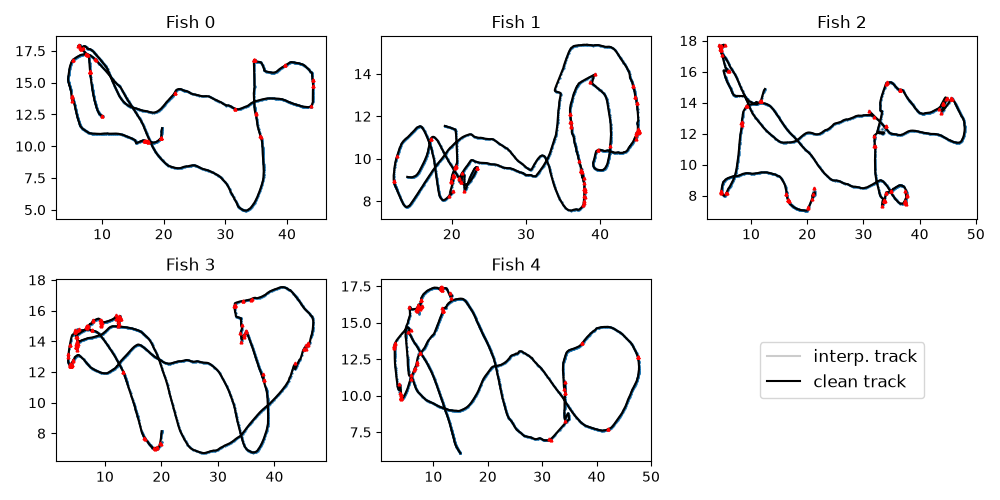

In [7]:
# Removing angle spikes

fig, ax = plt.subplots(2,3, figsize=(10, 5))
flat_axes = ax.flatten()
flat_axes[5].axis('off')

data_final_clean = np.zeros(data.shape)

positions = data_final.copy()
vectors = np.diff(positions, axis=1)

for i in range(no_of_fishes):
    x_temp = data_final[i, :, 0].copy()
    y_temp = data_final[i, :, 1].copy()
    vec_temp = np.squeeze(vectors[i,:,:]).copy()
    # flat_axes[i].plot(x_temp, y_temp, alpha=1)
    angle_spikes_temp = detect_angle_spikes(vec_temp, angle_threshold=0.0)
    
    # angle_spikes_temp[0], angle_spikes_temp[-1] = False, False
    x_temp_clean, y_temp_clean = clean_angle_spikes(x_temp, y_temp, angle_spikes_temp, vec_temp,cos_threshold=0.4, diff_threshold=0.4)

    x_interp_c = pd.Series(x_temp_clean).interpolate(method='pchip', limit_area='inside').to_numpy()
    y_interp_c = pd.Series(y_temp_clean).interpolate(method='pchip', limit_area='inside').to_numpy()

    data_final_clean[i, :, 0] = x_interp_c
    data_final_clean[i, :, 1] = y_interp_c
    flat_axes[i].plot(x_temp, y_temp, color='k', alpha=0.2, label='interp. track')
    flat_axes[i].scatter(x_temp, y_temp, alpha=1, s=0.4)
    print(i+1, x_temp[-1], y_temp[-1])
    flat_axes[i].plot(x_interp_c, y_interp_c, 'k', label='clean track')
    for j in angle_spikes_temp:
        flat_axes[i].plot(x_temp[j], y_temp[j], color='red', marker='^', markersize=2)

    flat_axes[i].set_title(f"Fish {i}")

handles, labels = flat_axes[0].get_legend_handles_labels()

flat_axes[5].legend(handles, labels, loc='center', fontsize=12)

plt.tight_layout()
plt.show()
plt.savefig("angle_spikes_loc.png", dpi=300, bbox_inches='tight')

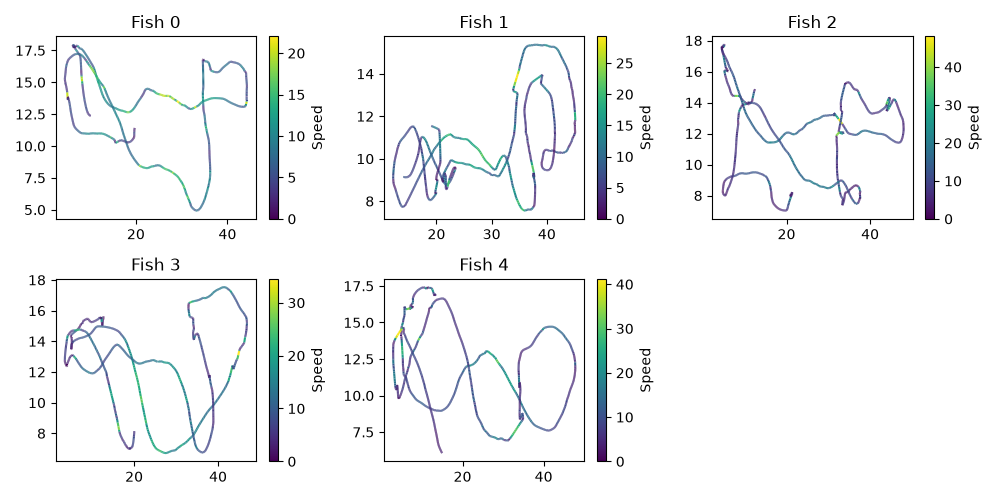

In [8]:
# Speedy trail of the corrected data
# interpolated plots speedy trails
fig, ax = plt.subplots(2, 3, figsize=(10,5))
flat_axes = ax.flatten()

flat_axes[5].axis('off')


for i in range(no_of_fishes):
    x_intp_speed = data_final_clean[i, :, 0]
    y_intp_speed = data_final_clean[i, :, 1]

    speedy_trail(x_intp_speed, y_intp_speed, flat_axes[i])
    # flat_axes[i].plot(x_interp, y_interp, color='black')
    flat_axes[i].set_title(f"Fish {i}")


# handles, labels = flat_axes[0].get_legend_handles_labels()

# flat_axes[5].legend(handles, labels, loc='center', fontsize=12)

plt.tight_layout()
plt.show()
plt.savefig("clean_speedy_trail.png", dpi=300, bbox_inches='tight')

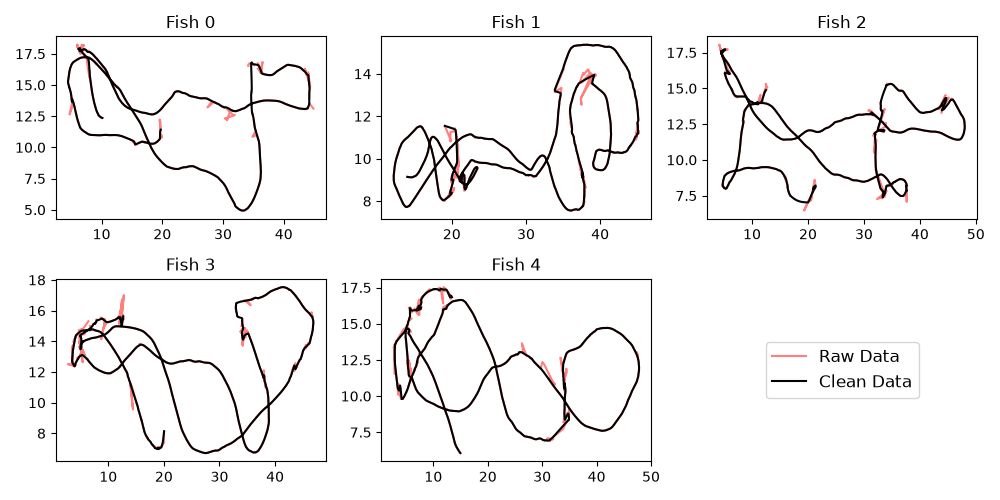

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(10,5))
flat_axes = ax.flatten()

# Turn off the 6th axis completely
flat_axes[5].axis('off')

for i in range(no_of_fishes):
    # Extract raw data
    x_raw = data[i, :, 0]
    y_raw = data[i, :, 1]
    
    # Extract clean data
    x_clean = data_final_clean[i, :, 0]
    y_clean = data_final_clean[i, :, 1]

    # Plot both on the same axis
    flat_axes[i].plot(x_raw, y_raw, color='red', alpha=0.5, label='Raw Data')
    flat_axes[i].plot(x_clean, y_clean, color='black', label='Clean Data')
    
    flat_axes[i].set_title(f"Fish {i}")

plt.tight_layout()

# Extract the legend from the first plot and place it in the center of the 6th axis
handles, labels = flat_axes[0].get_legend_handles_labels()
flat_axes[5].legend(handles, labels, loc='center', fontsize=12)

# IMPORTANT: savefig MUST be called before show!
plt.savefig("clean_vs_raw_trail.png", dpi=300, bbox_inches='tight')
plt.show()

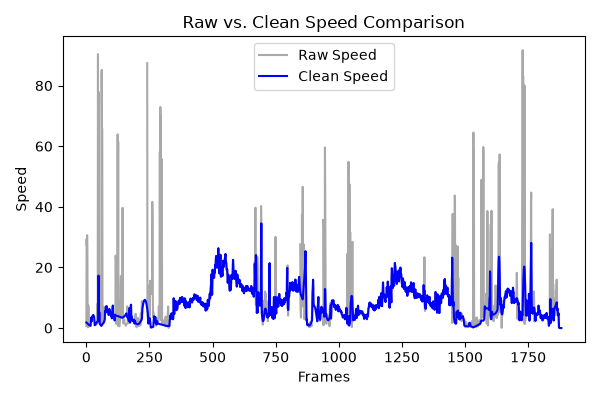

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming 'data' and 'data_final_clean' are already defined with shape (5, 1880, 2)
# and 'no_of_frames' is defined (e.g., no_of_frames = np.arange(1880))

# fig, ax = plt.subplots(1, 2, figsize=(10,4))

raw_data = data[3, :, :]
clean_data = data_final_clean[3, :, :]

sec_per_frame = 0.01

# Calculate velocities across the frame axis (axis=0) directly
vel_raw = np.gradient(raw_data, axis=0) / sec_per_frame
vel_clean = np.gradient(clean_data, axis=0) / sec_per_frame

# Calculate speeds
speed_raw = np.linalg.norm(vel_raw, axis=1)
speed_clean = np.linalg.norm(vel_clean, axis=1)

frame_indices = np.arange(speed_raw.shape[0])
# Plot results
fig, ax = plt.subplots(figsize=(6, 4))

# Plot raw speed in a lighter color or with transparency (alpha)
ax.plot(frame_indices, speed_raw, label='Raw Speed', color='darkgray', alpha=1)

# Plot clean speed on top in a bold color
ax.plot(frame_indices, speed_clean, label='Clean Speed', color='blue', linewidth=1.5)

ax.set_title('Raw vs. Clean Speed Comparison')
ax.set_xlabel('Frames')
ax.set_ylabel('Speed')

# Add a legend to distinguish the two lines
ax.legend()

plt.tight_layout()
plt.show()
plt.savefig("speed_ts_raw_vs_clean.png", dpi=300)

### Saving data


In [11]:
# change the file name if needed
file_name = parent_dir / "clean_tracks.npy"
np.save(file_name, data_final_clean)

### Creating tracked video



In [ ]:
# entirely written by gemini

def hex_to_bgr(hex_str):
    hex_str = hex_str.lstrip('#')
    # Extract RGB values and reverse them to BGR
    r, g, b = tuple(int(hex_str[i:i+2], 16) for i in (0, 2, 4))
    return (b, g, r)

video_path = '/run/media/hck03/Vivek/conditioning_experiments_cassandre_videos/Slow_motion_1C_4N/8nov/Clip0092_E2_4.mp4'
cap = cv2.VideoCapture(video_path)

# Get video properties for the writer
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# 5 Colorblind-friendly colors (Okabe-Ito palette) in Hex
hex_colors = [
    '#E69F00',  # Orange
    '#56B4E9',  # Sky Blue
    '#009E73',  # Bluish Green
    '#D55E00',  # Vermillion (Red-Orange)
    '#CC79A7'   # Reddish Purple
]

# Convert hex codes to OpenCV's required BGR format
colors = [hex_to_bgr(color) for color in hex_colors]

# Extract and scale data for all 5 fishes
num_fishes = 5
tracking_pixels_all = data_final_clean * (1 /  0.03650)

# Initialize the OpenCV Video Writer
fourcc = cv2.VideoWriter_fourcc(*'mp4v') # Codec for .mp4
output_path = parent_dir / 'marked_tracked_video.mp4'
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

frame_idx = 0
# Loop runs as long as we have frames and haven't exceeded our tracking data length
while cap.isOpened() and frame_idx < tracking_pixels_all.shape[1]:
    ret, frame = cap.read()
    if not ret:
        break # End of video
        
    # Iterate over each of the 5 fishes to draw their current position and path
    for fish_idx in range(num_fishes):
        color = colors[fish_idx]
        
        # Extract current pixel coordinates
        x = int(np.nan_to_num(tracking_pixels_all[fish_idx, frame_idx, 0]))
        y = int(np.nan_to_num(tracking_pixels_all[fish_idx, frame_idx, 1]))
        
        # Draw a solid circle on the frame at the fish's location
        cv2.circle(frame, (x, y), radius=4, color=color, thickness=-1)

        id_text = str(fish_idx)
        text_position = (x + 8, y - 8)
        cv2.putText(frame, id_text, text_position, cv2.FONT_HERSHEY_SIMPLEX, 
                    fontScale=0.7, color=color, thickness=2, lineType=cv2.LINE_AA)
        
        # Draw the trailing path
        if frame_idx > 0:
            # Get valid coordinates up to the current frame for this specific fish
            path_pts = tracking_pixels_all[fish_idx, :frame_idx+1].astype(np.int32)
            # Reshape for polylines: needs shape (number_of_points, 1, 2)
            path_pts = path_pts.reshape((-1, 1, 2))
            cv2.polylines(frame, [path_pts], isClosed=False, color=color, thickness=1)
    
    # Write the modified frame to the new video file
    out.write(frame)
    frame_idx += 1

# Release resources
cap.release()
out.release()


In [ ]:
# written by gemini
# to create single fish trajetories
def hex_to_bgr(hex_str):
    hex_str = hex_str.lstrip('#')
    r, g, b = tuple(int(hex_str[i:i+2], 16) for i in (0, 2, 4))
    return (b, g, r)

def draw_trajectory(frame, points, color, thickness=1):
    if len(points) < 2:
        return
        
    for i in range(1, len(points)):
        pt1 = points[i-1]
        pt2 = points[i]
        
        # Only draw the line segment if BOTH points are valid (not Inf, not NaN)
        if np.all(np.isfinite(pt1)) and np.all(np.isfinite(pt2)):
            coord1 = (int(pt1[0]), int(pt1[1]))
            coord2 = (int(pt2[0]), int(pt2[1]))
            cv2.line(frame, coord1, coord2, color, thickness)

video_path = '/home/hck03/Documents/MS_thesis/videos_folder/Clip0095_E2_7.mp4'
cap = cv2.VideoCapture(video_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

hex_colors = [
    '#E69F00', '#56B4E9', '#009E73', '#D55E00', '#CC79A7'
]
colors = [hex_to_bgr(color) for color in hex_colors]

num_fishes = 5
# Assuming 'data' and 'data_final_clean' are defined earlier in your script
tracking_pixels_raw = data * (1 / 0.03704)
tracking_pixels_cleaned = data_final_clean * (1 / 0.03704)

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
# Make sure parent_dir is defined (e.g., from pathlib import Path). 
# Wrap in str() to prevent OpenCV Pathlib errors.
output_path = str(parent_dir / 'marked_tracked_video_raw.mp4')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

frame_idx = 0
# Changed tracking_pixels_all to tracking_pixels_cleaned
while cap.isOpened() and frame_idx < tracking_pixels_cleaned.shape[1]:
    ret, frame = cap.read()
    if not ret:
        break
        
    fish_idx = 0
    color = colors[fish_idx]
    
    # Extract current pixel coordinates from the CLEANED data
    current_pt = tracking_pixels_cleaned[fish_idx, frame_idx]
    
    # Check if the current point is a valid number before drawing the head and ID
    if np.all(np.isfinite(current_pt)):
        x, y = int(current_pt[0]), int(current_pt[1])
        
        cv2.circle(frame, (x, y), radius=4, color=color, thickness=-1)
        
        id_text = str(fish_idx)
        text_position = (x + 8, y - 8)
        cv2.putText(frame, id_text, text_position, cv2.FONT_HERSHEY_SIMPLEX, 
                    fontScale=0.7, color=color, thickness=2, lineType=cv2.LINE_AA)

    if frame_idx > 0:
        start_idx = max(0, frame_idx - 30)
        
        pts_raw = tracking_pixels_raw[fish_idx, :frame_idx+1]
        pts_clean = tracking_pixels_cleaned[fish_idx, :frame_idx+1]
        
# Raw Trajectory: Light Gray (subtle background noise)
    draw_trajectory(frame, pts_raw, color=(255,255,255), thickness=2)

# Cleaned Trajectory: Matches the fish's ID dot (thick and prominent)
    draw_trajectory(frame, pts_clean, color=colors[fish_idx], thickness=2)
    
    out.write(frame)
    frame_idx += 1

cap.release()
out.release()

### All trajectories plot


In [ ]:
# grand plot 

length = 10
# aspect_x, aspect_y = 1380, 596
fig = plt.figure(figsize=(length,(length/(50/20))))
ax = fig.add_axes([0, 0, 1, 1])
# ax.axis('off')
xmin, xmax = 0, 50
ymin, ymax = 0, 50/(50/20)


ax.set_xticks([])
ax.set_yticks([])
mid_way = (np.nanmin(data_final[:,:,0]) + np.nanmax(data_final[:,:,0]))/2
ax.axvline(x=22)
ax.axvline(x=30.5)


for i in range(no_of_fishes):
    track = data_final[i, :, :]
    track_x = track[:,0]
    track_y = track[:,1]
    
    # ax.invert_xaxis()
    ax.plot(track_x, track_y, label = f"fish {i+1}")
ax.invert_yaxis()
# img = plt.imread('/home/hck03/Documents/MS_thesis/tracking_output/1c_4n_faulty/Clip0070_1C_4N_E3_8/average_Clip0070_1C_4N_E3_8.png')
# ax.imshow(img, extent=[xmin, xmax, ymin, ymax], aspect='auto', zorder=0)
ax.legend(loc = "upper left", framealpha = 0.5)